<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/PCVK_Ganjil_2026-2027_FadhilTaufiqurrachman/blob/main/Week7PCVK.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pertemuan 7 - Segmentasi Citra Dengan Thresholding

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pengolahan Citra Dan Visi Komputer

In [1]:
# Inisialisasi Identitas Mahasiswa
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Fadhil Taufiqurrachman'
NIM = '244107020090'

waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])

NAMA   : Fadhil Taufiqurrachman
NIM    : 244107020090
WAKTU  : 2026-10-12 21:26:05 WIB
SISTEM : 3.13.16 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 4fbfcf6e01127bcb


### D. Tugas Praktikum

**D1. Praktikum Individu**

1. Menyambungkan Ke Google Drive Dan Inisialisasi Folder Image

In [2]:
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File /PCVK Image/'

Mounted at /content/drive


2. Import Library Yang Akan Digunakan

In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3. Membuat Global Threshold

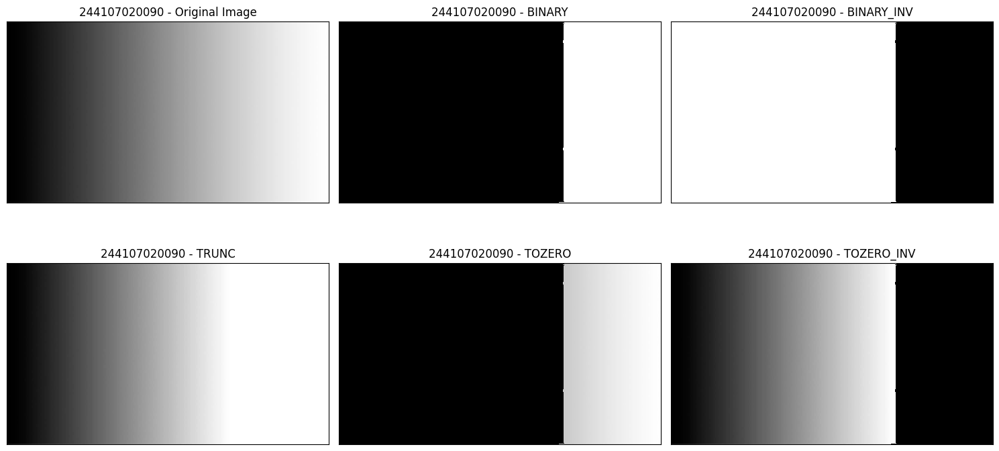

In [4]:
# Membaca Citra KTM1d
filename = BASE_PATH + 'gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

# Menentukan Nilai Ambang (Threshold) Dan Nilai Maksimal Sesuai Soal
thresh = 200
maxval = 255

# Inisialisasi Matriks Kosong Untuk Masing-masing Hasil Threshold
thresh_binary = np.zeros_like(img)
thresh_binary_inv = np.zeros_like(img)
thresh_trunc = np.zeros_like(img)
thresh_tozero = np.zeros_like(img)
thresh_tozero_inv = np.zeros_like(img)

# Mendapatkan Ukuran Baris Dan Kolom Gambar
row, col = img.shape

# Melakukan Looping Untuk Mengecek Dan Mengubah Nilai Setiap Piksel Secara Manual
for i in range(row):
    for j in range(col):
        # Menyimpan Nilai Piksel Saat Ini
        pixel_val = img[i, j]

        # 1. Logika Threshold Binary
        if pixel_val > thresh:
            thresh_binary[i, j] = maxval
        else:
            thresh_binary[i, j] = 0

        # 2. Logika Threshold Binary Inverted
        if pixel_val > thresh:
            thresh_binary_inv[i, j] = 0
        else:
            thresh_binary_inv[i, j] = maxval

        # 3. Logika Threshold Truncate
        if pixel_val > thresh:
            thresh_trunc[i, j] = thresh
        else:
            thresh_trunc[i, j] = pixel_val

        # 4. Logika Threshold To Zero
        if pixel_val > thresh:
            thresh_tozero[i, j] = pixel_val
        else:
            thresh_tozero[i, j] = 0

        # 5. Logika Threshold To Zero Inverted
        if pixel_val > thresh:
            thresh_tozero_inv[i, j] = 0
        else:
            thresh_tozero_inv[i, j] = pixel_val

# Menyiapkan Judul Dan Gambar Untuk Ditampilkan Dengan Matplotlib
titles = ['244107020090 - Original Image', '244107020090 - BINARY', '244107020090 - BINARY_INV',
          '244107020090 - TRUNC', '244107020090 - TOZERO', '244107020090 - TOZERO_INV']
images = [img, thresh_binary, thresh_binary_inv, thresh_trunc, thresh_tozero, thresh_tozero_inv]

# Membuat Figure Dan Menampilkan Semua Gambar
plt.figure(figsize=(15, 8))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Mencoba membuat lima jenis Global Threshold (Binary, Binary Inverted, Truncate, To Zero, dan To Zero Inverted) secara manual tanpa menggunakan pustaka cv.threshold dari OpenCV. Proses ini menggunakan dua perulangan berlapis (nested loops) yang secara sekuensial akan memeriksa nilai intensitas setiap individu piksel pada citra asli. Nilai setiap piksel tersebut kemudian dibandingkan terhadap nilai ambang batas (threshold) tunggal yang telah ditetapkan, yaitu 200. Apabila nilai piksel tersebut melebihi batas ambang, maupun jika nilainya kurang dari atau sama dengan batas ambang, piksel akan dimodifikasi sesuai dengan peraturan matematis masing masing dari kelima teknik thresholding tersebut.

4. Membuat Addaptive Threshold

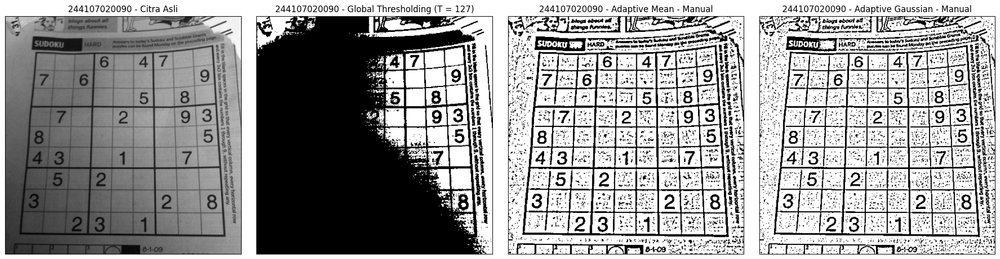

In [5]:
# Membaca Citra Sudoku
filename = BASE_PATH + 'sudoku-original.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

# Parameter Thresholding
global_thresh_val = 127
block_size = 11
C = 2
sigma = 2
# Menghitung Padding
pad = block_size // 2

global_thresh = np.zeros_like(img)
adaptive_mean = np.zeros_like(img)
adaptive_gaussian = np.zeros_like(img)

# Menambahkan Padding Pada Citra Untuk Memproses Tepi Gambar (Metode Edge)
img_padded = np.pad(img, pad, mode='edge')

# Membuat Kernel Gaussian 11x11 Secara Manual
x, y = np.mgrid[-pad:pad+1, -pad:pad+1]
# Menerapkan Rumus Distribusi Gaussian 2D
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
# Normalisasi Kernel
gaussian_kernel = gaussian_kernel / gaussian_kernel.sum()

row, col = img.shape

# Looping Setiap Piksel Secara Manual Untuk Mencari Ambang Batas Lokal
for i in range(row):
    for j in range(col):
        # 1. Global Thresholding Manual
        pixel_val = img[i, j]
        if pixel_val > global_thresh_val:
            global_thresh[i, j] = 255
        else:
            global_thresh[i, j] = 0

        # 2. Mendapatkan Area Jendela (Window)
        window = img_padded[i:i+block_size, j:j+block_size]

        # 3. Adaptive Mean Thresholding Manual
        mean_val = np.mean(window)
        if pixel_val > (mean_val - C):
            adaptive_mean[i, j] = 255
        else:
            adaptive_mean[i, j] = 0

        # 4. Adaptive Gaussian Thresholding Manual
        gaussian_val = np.sum(window * gaussian_kernel)
        if pixel_val > (gaussian_val - C):
            adaptive_gaussian[i, j] = 255
        else:
            adaptive_gaussian[i, j] = 0

titles = ['244107020090 - Citra Asli',
          '244107020090 - Global Thresholding (T = 127)',
          '244107020090 - Adaptive Mean - Manual',
          '244107020090 - Adaptive Gaussian - Manual']
images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(20, 5))
for i in range(len(images)):
    plt.subplot(1, 4, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Percobaan ini menyimulasikan beberapa metode thresholding. Yang pertama yakni Adaptive Thresholding secara manual, langkah yang terpenting adalah memberikan padding sehingga mencegah out of bounds. Kemudian ada Adaptive Mean, yaitu ambang batas lokal dihitung dengan mencari nilai rata rata dari semua piksel. Sedangkan Adaptive Gaussian akan dikalikan dengan matriks kernel gaussian.

5. Membuat Otsu Thresholding

A. Otsu Thresholding Pada Citra Lena

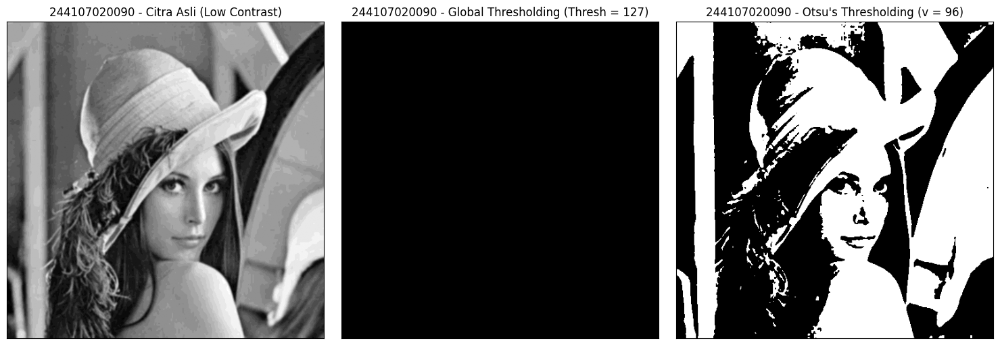

In [6]:
# Membaca Citra Lena Dan Mengonversi Ke Grayscale
filename = BASE_PATH + 'lena.jpg'
img = cv.imread(filename, 0)

# Mensimulasikan Kondisi Low Contrast (Intensitas 85 - 108)
img_low_contrast = cv.normalize(img, None, 85, 108, cv.NORM_MINMAX)

# Gaussian Blur
blur = cv.GaussianBlur(img_low_contrast, (5, 5), 0)

# Ambang Batas Global
thresh = 127

# Mendefinisikan Fungsi Otsu Secara Manual
def otsu(gray):
    # Menghitung Total Piksel Dan Bobot Rata-rata
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number

    # Membuat Histogram Citra
    his, bins = np.histogram(gray, np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    # Mencari Nilai Threshold (T) Terbaik
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        # Mencegah Error Pembagian Dengan Nol
        if pcb == 0 or pcf == 0:
            continue

        # Menghitung Bobot Background Dan Foreground
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        # Menghitung Rata-rata (Mean) Background Dan Foreground
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        # Menghitung Between Class Variance
        value = Wb * Wf * (mub - muf) ** 2

        # Mencari Nilai Variance Maksimal
        if value > final_value:
            final_thresh = t
            final_value = value

    # Menerapkan Nilai Threshold Terpilih Ke Dalam Citra
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0

    return final_img, final_thresh

# Menjalankan Fungsi Otsu Manual
otsu_biner, otsu_thresh = otsu(blur)

# Menjalankan Global Thresholding Sebagai Pembanding
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

x = "244107020090 - Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['244107020090 - Citra Asli (Low Contrast)',
          '244107020090 - Global Thresholding (Thresh = ' + str(thresh) + ')',
          x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(15, 5))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Algoritma metode ini mencari semua kemungkinan nilai ambang batas dari 0 hingga 255 dan dengan menghitung bobot serta rata-rata intensitas dari background dan foreground. Threshold terbaik akan ditentukan pada titik di mana nilai Between Class Varians mencapai puncaknya. Dari hasil dapat disimpulkan bahwa nilai T yang global secara statis menghasilkan citra hitam karena nilai piksel kurang dari 127 sehingga akan diubah menjadi nilai 0. Sedangkan metode Otsu dapat beradaptasi untuk mencari nilai thresholding yang sesuai secara mandiri.

/tmp/ipykernel_1061/1246729189.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256])


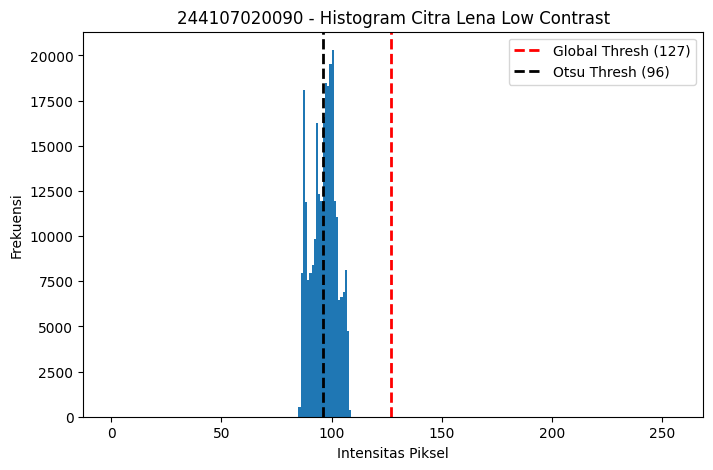

In [7]:
# Membuat Plot Histogram Untuk Menganalisis Gambar Lena Low Contrast
plt.figure(figsize=(8, 5))
# Meratakan Array Citra Ke 1D Dan Menghitung Distribusi
plt.hist(blur.ravel(), 256, [0, 256])
# Global Threshold (Merah) Dan Otsu (Hitam)
plt.axvline(x=127, color='r', linestyle='dashed', linewidth=2, label='Global Thresh (127)')
plt.axvline(x=otsu_thresh, color='k', linestyle='dashed', linewidth=2, label=f'Otsu Thresh ({otsu_thresh})')

plt.title('244107020090 - Histogram Citra Lena Low Contrast')
plt.xlabel('Intensitas Piksel')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()

Hasil dari Binary Thresholding (Global) bernilai 0 hitam semua dikarenakan citra Lena yang diproses merupakan citra berkontras rendah (low contrast) dengan rentang distribusi intensitas piksel yang sangat sempit, yaitu hanya menumpuk pada sekitar angka 85 hingga 108. Karena T ditentukan secara global dan statis yaitu bernilai 127, maka nilai piksel yang berada di bawah nilai ambang batas 127 akan dikonversi menjadi 0 (Hitam) semua.

B. Otsu Thresholding Pada Citra KTP

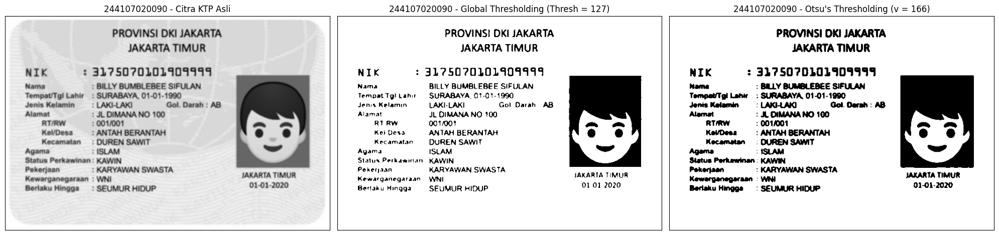

In [8]:
# Membaca Citra KTP Dan Mengonversi Ke Grayscale
filename_ktp = BASE_PATH + 'ktp_fulan.jpg'
img_ktp = cv.imread(filename_ktp, 0)

# Gaussian Blur
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

# Memanggil Fungsi Otsu Manual
otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)

# Menjalankan Global Thresholding (T=127) Sebagai Pembanding
ret_ktp, th1_ktp = cv.threshold(blur_ktp, 127, 255, cv.THRESH_BINARY)

x_ktp = "244107020090 - Otsu's Thresholding (v = " + str(otsu_thresh_ktp) + ")"
titles_ktp = ['244107020090 - Citra KTP Asli',
              '244107020090 - Global Thresholding (Thresh = 127)',
              x_ktp]
citra3_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize=(20, 5))
for i in range(len(citra3_ktp)):
    plt.subplot(1, 3, i+1)
    plt.imshow(citra3_ktp[i], 'gray')
    plt.title(titles_ktp[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Percobaan ini membuktikan kelemahan dari Global Thresholding statis. Menggunakan ambang batas statis dapat merusak keterbacaan teks karena faktor tertentu seperti pantulan cahaya, bayangan atau tekstur background. Sedangkan jika menggunakan Otsu, metode ini akan menyesuaikan sesuai nilai piksel yang bersangkutan. Sehingga pemisahan foreground dan background jauh lebih presisi dan optimal

6. Membuat Segmentasi

A. Segmentasi Berbasis Region (Manual Region Growing)

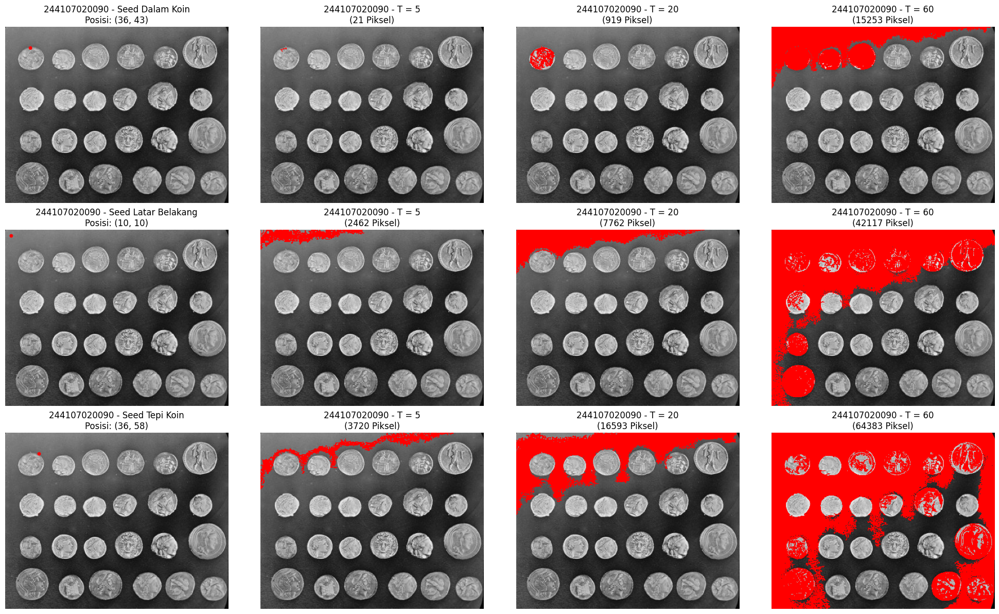

In [9]:
# Fungsi Region Growing Manual
def region_growing_manual(img, seed, tolerance):
    # Inisialisasi Matriks Mask (Hasil) Dan Antrian (Queue)
    mask = np.zeros_like(img, dtype=np.uint8)
    h, w = img.shape
    queue = deque([seed])

    # Mencatat Intensitas Warna Pada Titik Seed Awal
    seed_intensity = float(img[seed[0], seed[1]])
    mask[seed[0], seed[1]] = 1
    pixel_count = 1

    # Arah Penelusuran 4-Ketetanggaan (Atas, Bawah, Kiri, Kanan)
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    # Looping Selama Masih Ada Piksel Tetangga Yang Memenuhi Syarat
    while queue:
        r, c = queue.popleft()

        for dr, dc in directions:
            nr, nc = r + dr, c + dc

            # Memastikan Piksel Tetangga Berada Di Dalam Batas Gambar
            if 0 <= nr < h and 0 <= nc < w:
                # Mengecek Apakah Piksel Belum Pernah Dievaluasi
                if mask[nr, nc] == 0:
                    # Syarat Utama: Selisih Intensitas Harus Di Dalam Batas Toleransi (T)
                    if abs(float(img[nr, nc]) - seed_intensity) <= tolerance:
                        mask[nr, nc] = 1
                        queue.append((nr, nc))
                        pixel_count += 1

    return mask, pixel_count

# Memuat Citra Koin Bawaan Dari Modul Skimage
gray = data.coins()

# Menentukan 3 Titik Seed (Baris, Kolom) Sesuai Ketentuan Soal
# 1. (36, 43) -> Di Dalam Koin
# 2. (10, 10) -> Di Latar Belakang Hitam
# 3. (36, 58) -> Di Tepi Koin
seeds = [(36, 43), (10, 10), (36, 58)]
seed_names = ["Dalam Koin", "Latar Belakang", "Tepi Koin"]
thresholds = [5, 20, 60]

# Menyiapkan Figure Untuk Grid 3 (Seed) x 4 (1 Asli + 3 Threshold)
plt.figure(figsize=(20, 12))

# Melakukan Looping Untuk Setiap Seed Dan Setiap Threshold
for i, seed in enumerate(seeds):
    # Membuat Visualisasi Citra Asli + Titik Seed Merah
    img_seed = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
    cv.circle(img_seed, (seed[1], seed[0]), 3, (255, 0, 0), -1)

    plt.subplot(3, 4, i * 4 + 1)
    plt.imshow(img_seed)
    plt.title(f'244107020090 - Seed {seed_names[i]}\nPosisi: {seed}')
    plt.axis('off')

    for j, T in enumerate(thresholds):
        # Menjalankan Fungsi Region Growing Manual
        mask, count = region_growing_manual(gray, seed, T)

        # Membuat Overlay Warna Merah Untuk Area Yang Tersegmentasi
        img_result = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
        img_result[mask == 1] = [255, 0, 0]

        plt.subplot(3, 4, i * 4 + 2 + j)
        plt.imshow(img_result)
        plt.title(f'244107020090 - T = {T}\n({count} Piksel)')
        plt.axis('off')

plt.tight_layout()
plt.show()

Metode Region Growing akan melihat proses segmentasi sebagai penyebaran yang berawal dari sebuah seed point, lalu menumbuhkan area tersebut dengan cara mengambil piksel-piksel bertetangga yang memiliki karakteristik homogen dengan titik asal. Pemilihan lokasi seed sangat menentukan keberhasilan ekstraksi, seed yang diletakkan tepat di tengah objek koin akan menyebar secara merata dan terisolasi dengan baik jika nilai toleransi (T) dikalibrasi secara proporsional. Namun, jika toleransi T terlalu kecil (misal T=5), pertumbuhan wilayah akan terhenti sangat awal karena tekstur permukaan koin yang sedikit noisy, menyebabkan region tampak berlubang atau terpecah. Sebaliknya, jika T terlalu besar (misal T=60), kriteria kesamaan menjadi terlalu longgar sehingga area segmentasi bocor keluar dari objek koin, menyatu dengan latar belakang, bahkan merambat ke objek koin lainnya di sekitar. Eksperimen ini membuktikan bahwa metode berbasis wilayah sangat bergantung pada dua variabel utama, yakni titik awal seed dan ketatnya aturan syarat penerimaan anggota wilayah (threshold).

B. Menggunakan fungsi bawaan

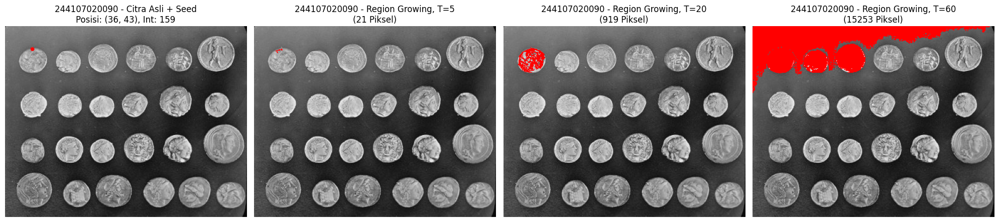

In [10]:
# Menyiapkan Titik Seed
seed_flood = (36, 43)
tolerances = [5, 20, 60]

# Menyiapkan Figure Untuk Visualisasi 1 Baris x 4 Kolom
plt.figure(figsize=(20, 5))

# 1. Menampilkan Citra Asli Ditambah Indikator Seed Merah
img_seed_flood = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
cv.circle(img_seed_flood, (seed_flood[1], seed_flood[0]), 3, (255, 0, 0), -1)
seed_intensity = gray[seed_flood[0], seed_flood[1]]

plt.subplot(1, 4, 1)
plt.imshow(img_seed_flood)
plt.title(f'244107020090 - Citra Asli + Seed\nPosisi: {seed_flood}, Int: {seed_intensity}')
plt.axis('off')

# 2. Menjalankan Looping Flood Fill Sesuai Daftar Toleransi
for i, tol in enumerate(tolerances):
    # Segmentasi Menggunakan Fungsi Siap Pakai (Flood)
    # Connectivity=1 Berarti Menggunakan 4-Ketetanggaan (Atas, Bawah, Kiri, Kanan)
    region = flood(gray, seed_point=seed_flood, tolerance=tol, connectivity=1)

    # Menghitung Jumlah Piksel Yang Terpilih
    pixel_count = np.sum(region)

    # Membuat Overlay Merah Pada Citra Untuk Area Region
    img_result = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
    img_result[region] = [255, 0, 0]

    plt.subplot(1, 4, i + 2)
    plt.imshow(img_result)
    plt.title(f'244107020090 - Region Growing, T={tol}\n({pixel_count} Piksel)')
    plt.axis('off')

plt.tight_layout()
plt.show()

Fungsi skimage.segmentation.flood() merupakan implementasi algoritma tingkat lanjut dari region growing, yaitu flood-fill algorithm. Cara kerjanya sangat identik dengan algoritma manual yang dibangun sebelumnya, fungsi ini menyerap piksel bertetangga yang intensitas warnanya masih berada di dalam batas deviasi tolerance terhadap intensitas piksel seed awal. Menggunakan fungsi library bawaan ini sangat direkomendasikan untuk produksi skala besar karena telah dioptimasi secara komputasional pada memori tingkat dasar, menjadikannya jauh lebih efisien dari segi waktu dan beban pemrosesan dibandingkan eksekusi looping manual dengan struktur data antrian konvensional di Python.

7. Membuat Segmentasi Warna

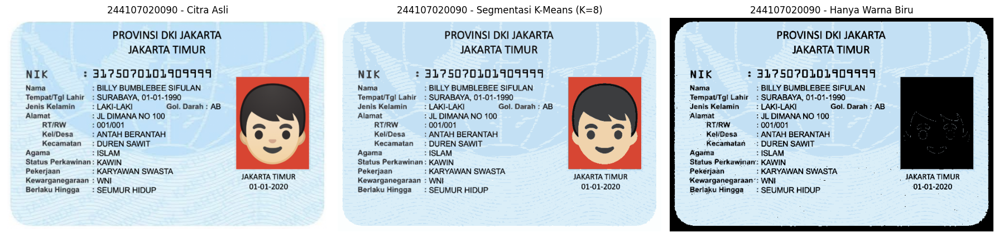

In [11]:
# Mengimpor Library KMeans Dari Scikit-Learn
from sklearn.cluster import KMeans

filename_ktp = BASE_PATH + 'ktp_fulan.jpg'
img_bgr = cv.imread(filename_ktp)
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Mengubah Dimensi Citra Menjadi Array 2D (Jumlah Piksel x 3 Kanal Warna)
Z = img_rgb.reshape((-1, 3))
Z = np.float32(Z)

# Menentukan Jumlah Cluster K=8 Dan Menjalankan Algoritma K-Means
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(Z)

# Mendapatkan Label Setiap Piksel Dan Pusat Cluster (Centroid) Dalam Bentuk Uint8
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# Membentuk Citra Hasil Segmentasi K-Means (K=8)
segmented_data = centers[labels.flatten()]
segmented_img = segmented_data.reshape(img_rgb.shape)

# Mengonversi Pusat Cluster (Centroid) Dari Rgb Ke Ruang Warna Hsv
centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
H = centers_hsv[:, 0]
S = centers_hsv[:, 1]
V = centers_hsv[:, 2]

# Mencari Indeks Cluster Yang Termasuk Dalam Rentang Warna Biru Pada Latar Ktp
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))[0]

# Membuat Salinan Centroid Baru Yang Hanya Menyimpan Warna Dari Kelompok Biru
# Cluster Selain Warna Biru Akan Diubah Menjadi Warna Hitam (0, 0, 0)
centers_biru = np.zeros_like(centers)
centers_biru[kelompok_biru] = centers[kelompok_biru]

# Membentuk Citra Akhir Yang Hanya Menampilkan Cluster Warna Biru
biru_data = centers_biru[labels.flatten()]
biru_img = biru_data.reshape(img_rgb.shape)

titles = ['244107020090 - Citra Asli',
          '244107020090 - Segmentasi K-Means (K=8)',
          '244107020090 - Hanya Warna Biru']
images = [img_rgb, segmented_img, biru_img]

plt.figure(figsize=(18, 6))
for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

Segmentasi warna pada citra ktp_fulan.jpg mengombinasikan metode unsupervised clustering K-Means dengan penyaringan ruang warna HSV (Hue, Saturation, Value). Pada tahap pertama, seluruh piksel citra RGB dipetakan menjadi kumpulan vektor dua dimensi dan dikelompokkan ke dalam $K=8$ klaster warna dominan menggunakan algoritma K-Means untuk melakukan kuantisasi warna. Selanjutnya, ke-8 nilai pusat klaster (centroid) yang terbentuk dikonversi dari ruang warna RGB ke HSV karena model warna HSV mampu memisahkan komponen rona warna murni (Hue) dari kepekatan (Saturation) dan tingkat kecerahan (Value). Dengan menerapkan seleksi kondisi logika pada komponen HSV (85 <= H <= 130, S >= 25, dan V >= 40), program secara selektif hanya mempertahankan centroid yang merepresentasikan warna biru muda pada latar belakang KTP dan mengubah centroid klaster lainnya (seperti latar foto berwarna merah, warna kulit pada foto, dan tepian putih kartu) menjadi piksel hitam.

**D2. Tugas Kelompok**

In [12]:
# Menginstal Mesin Tesseract Ocr Dan Model Bahasa Indonesia Di Google Colab
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

# Mengimpor Library Pytesseract Dan Modul Pendukung Evaluasi Teks
import pytesseract
from pytesseract import Output
import difflib
from IPython.display import display

# Mendefinisikan Data Acuan 10 Kata Atau Angka Untuk 4 Citra Ktp Anggota Kelompok
data_ktp = {
    'ktp_fadhil.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'FADHIL', 'TAUFIQURRACHMAN', '08-06-2006', 'PURWOASRI', 'SINGOSARI', 'WNI', '07-05-2024'],
    'ktp_fattah.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'MUHAMMAD', 'FATTAHUL', 'ALIM', '15-12-2006', 'SINGOSARI', 'WNI', '19-01-2024'],
    'ktp_hafsyah.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'MUFLIHA', 'HAFSYAH', 'SHAHIEZA', '19-12-2005', 'SUKUN', 'WNI', '13-02-2024'],
    'ktp_abid.jpeg': ['JAWA', 'TIMUR', 'ISLAM', 'NAUFAL', 'ABID', 'AURIZKY', '29-07-2005', 'LAWANG', 'WNI', '19-10-2022']
}

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


1. Menyiapkan Tiga Citra untuk Dibandingkan (Berwarna, Otsu, dan Adaptive)

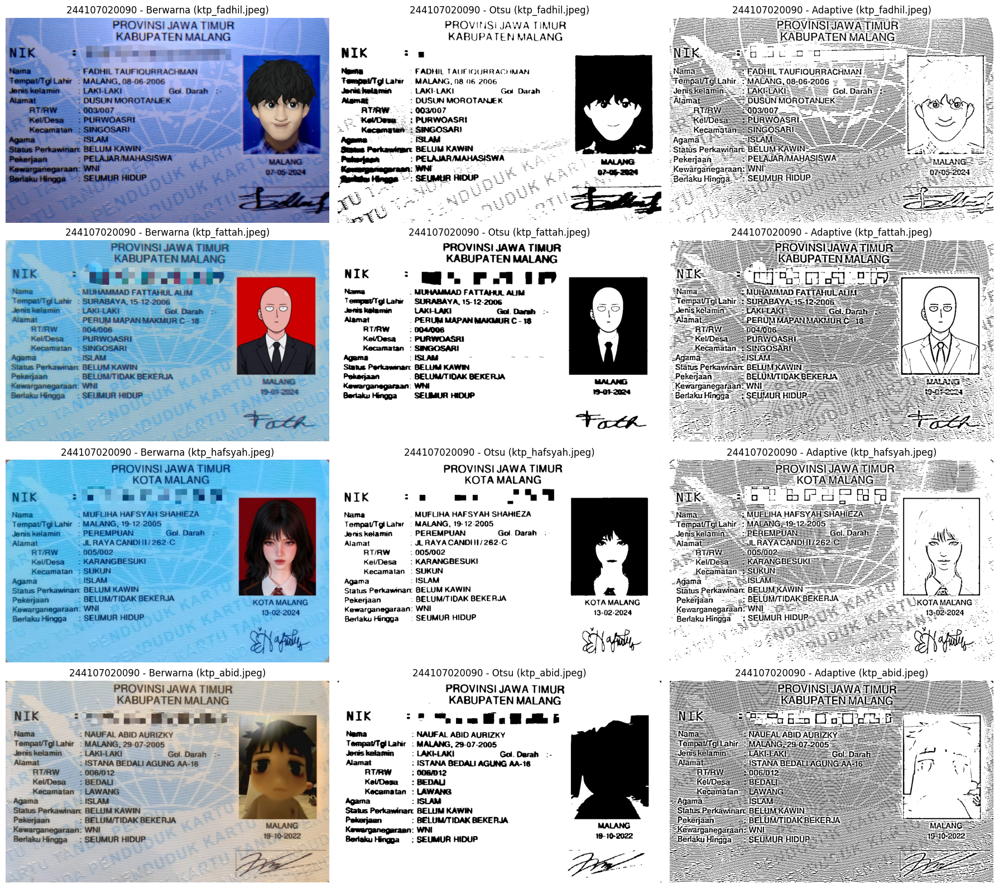

In [13]:
preprocessed_ktp = {}

# Membuat Figure Untuk Menampilkan Perbandingan 3 Citra Pada 4 Ktp Anggota
plt.figure(figsize=(18, 16))

# Melakukan Iterasi Untuk Setiap File Ktp Di Dalam Dictionary
for idx, (filename, _) in enumerate(data_ktp.items()):
    # Membaca Citra Ktp Dan Mengonversi Ke Rgb Serta Grayscale Dengan Ukuran Sama
    img_path = BASE_PATH + filename
    img_bgr = cv.imread(img_path)
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_bgr, cv.COLOR_BGR2GRAY)

    img_blur = cv.GaussianBlur(img_gray, (3, 3), 0)

    # 1. Membuat Citra Hasil Segmentasi Otsu Thresholding
    _, img_otsu = cv.threshold(img_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 2. Membuat Citra Hasil Segmentasi Adaptive Thresholding (Gaussian)
    img_adaptive = cv.adaptiveThreshold(
        img_blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 15, 8
    )

    preprocessed_ktp[filename] = {
        'Berwarna asli': img_rgb,
        'Segmentasi Otsu': img_otsu,
        'Segmentasi Adaptive': img_adaptive
    }

    plt.subplot(4, 3, idx * 3 + 1)
    plt.imshow(img_rgb)
    plt.title(f'244107020090 - Berwarna ({filename})')
    plt.axis('off')

    plt.subplot(4, 3, idx * 3 + 2)
    plt.imshow(img_otsu, cmap='gray')
    plt.title(f'244107020090 - Otsu ({filename})')
    plt.axis('off')

    plt.subplot(4, 3, idx * 3 + 3)
    plt.imshow(img_adaptive, cmap='gray')
    plt.title(f'244107020090 - Adaptive ({filename})')
    plt.axis('off')

plt.tight_layout()
plt.show()

2. Pembacaan Teks pada Ketiga Citra Menggunakan pytesseract.image_to_string()

In [14]:
# Menentukan Konfigurasi Bahasa Dan Page Segmentation Mode (Psm) Yang Konsisten
ocr_config = '--oem 3 --psm 6'
ocr_lang = 'ind'

# Menyimpan Hasil Teks String Dari Setiap Metode Ocr Untuk Semua Ktp
ocr_texts = {}

# Melakukan Pembacaan Teks Untuk Setiap Ktp Dan Setiap Metode Citra Masukan
for filename, images_dict in preprocessed_ktp.items():
    ocr_texts[filename] = {}
    print(f"============================================================")
    print(f"HASIL PEMBACAAN OCR UNTUK FILE: {filename.upper()}")
    print(f"============================================================\n")

    for method_name, img_data in images_dict.items():
        # Mengekstrak Teks Menggunakan Pytesseract Image_To_String
        extracted_text = pytesseract.image_to_string(img_data, lang=ocr_lang, config=ocr_config)
        ocr_texts[filename][method_name] = extracted_text

        # Menampilkan Hasil Teks Sesuai Format Pada Modul
        print(f"========== {method_name.upper()} ({filename}) ==========")
        print(extracted_text.strip())
        print("\n")

HASIL PEMBACAAN OCR UNTUK FILE: KTP_FADHIL.JPEG

========== BERWARNA ASLI (ktp_fadhil.jpeg) ==========
pe PROVINSI JAWA TIMUR PA
 — KABUPATEN MALANG —
NIK AA P1 w 5.
Nama — ——— FADHIL TAUFIOURRACHMAN
: giLahir — MALANG, 08-06-2006 2
niskelamin-. : LAKI-LAKI Gol. Darah —

Mamat ——-: DUSUN MOROTANJEK — Ge hun 2
—— RTRW 003007 5 N y E
AT

Status Perkawinarr BELUM KAWIN ——— — ———-- -. A 3
Pekerjaan — — : PELAJAR/MAHASISWA —- —--———.. 3
SS 5 dg
—— Te “AA,
aa


========== SEGMENTASI OTSU (ktp_fadhil.jpeg) ==========
PROVINSI JAWA TIMUR
KABUPATEN MALANG
NIK 2.
Nana : FADHIL TAUFTOURRACHMAN
Tempat'Tgi Lahir . MALANG, 08 06 2006
Jerigelarun LAKI-LAKI Gol Darah -
Mamat —.1 DUSUN MOROTANJEK AA Ka
RTRW. -. : 901007 '
5 KelDesa 1 PURWOASRI
25 Kecamgtan - SINGOSARI
Agama - an ISLAM 3 .
Status Perkamar BELUM KAWIN ——-——.““— 4 ya
Pekerjaan: PELAJARMAHASISWA UANG”
Kewarganegaraan: WNI 5 Te “ LE En |. 8 " 006-204
Makati Hraga —: SEUMUR HIDUP — 55. 5. ta.
. ru - P5. Daeng —- 0.


========== SEGMENTASI AD

3. Menampilkan Area Teks yang Dikenali (pytesseract.image_to_data()) dan Kotak Hijau

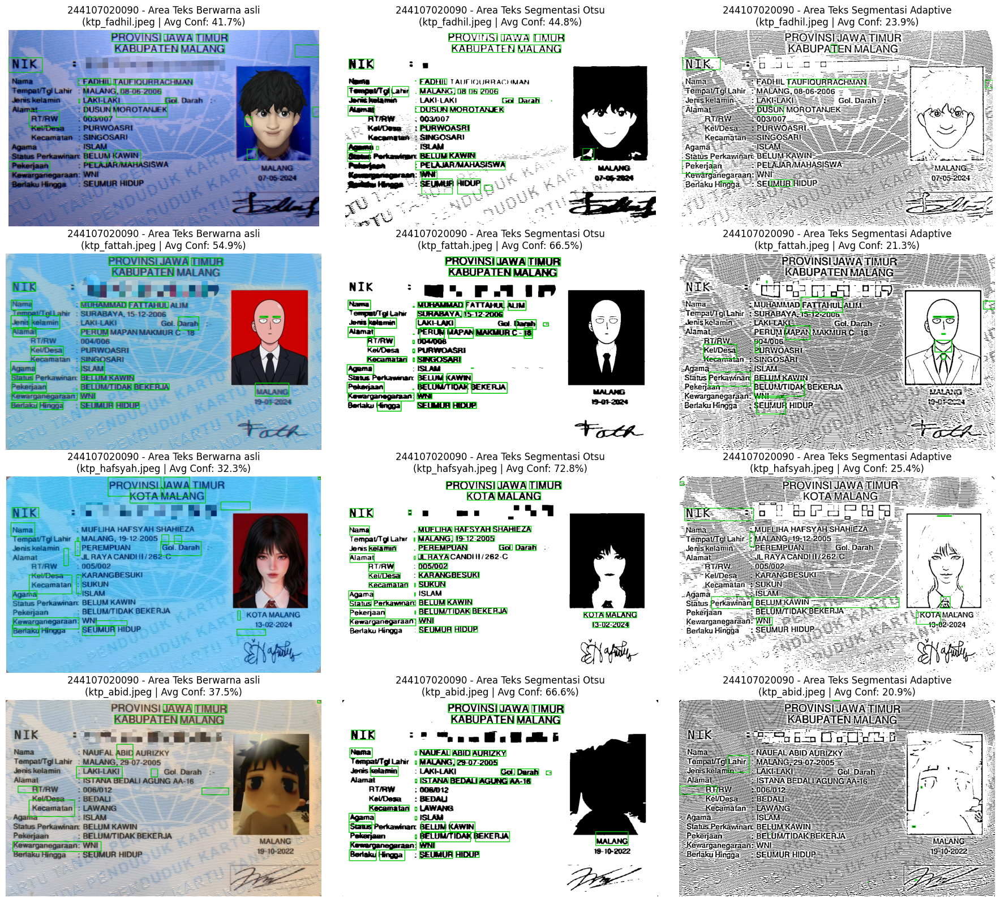

In [15]:
# Menentukan Batas Ambang Confidence
conf_threshold = 60

# Menyimpan Nilai Confidence Untuk Perhitungan Tabel Ringkasan Di Nomor 5
ocr_confidences = {}

# Membuat Figure Untuk Menampilkan Kotak Hijau Area Teks Pada Keempat Ktp
plt.figure(figsize=(18, 16))

# Melakukan Iterasi Untuk Setiap Ktp Dan Ketiga Variasi Citra
for idx, (filename, images_dict) in enumerate(preprocessed_ktp.items()):
    ocr_confidences[filename] = {}

    for m_idx, (method_name, img_data) in enumerate(images_dict.items()):
        # Mengonversi Citra Biner Ke Rgb Agar Kotak Hijau Dapat Terlihat Berwarna
        if len(img_data.shape) == 2:
            img_box = cv.cvtColor(img_data, cv.COLOR_GRAY2RGB)
        else:
            img_box = img_data.copy()

        # Mendapatkan Data Koordinat Kotak Dan Nilai Confidence Dari Pytesseract
        data_ocr = pytesseract.image_to_data(
            img_data, lang=ocr_lang, config=ocr_config, output_type=Output.DICT
        )

        valid_confs = []
        n_boxes = len(data_ocr['level'])

        # Mengecek Setiap Kata Yang Terdeteksi Oleh Mesin Ocr
        for i in range(n_boxes):
            # Mengambil Nilai Confidence Dan Teks Kata
            conf_val = float(data_ocr['conf'][i])
            word_text = data_ocr['text'][i].strip()

            # Menyimpan Confidence Untuk Semua Kata Valid Yang Terbaca Oleh Mesin
            if conf_val >= 0 and word_text != "":
                valid_confs.append(conf_val)

            # Menggambar Kotak Hijau Jika Nilai Confidence Lebih Dari 60
            if conf_val > conf_threshold and word_text != "":
                x, y, w, h = data_ocr['left'][i], data_ocr['top'][i], data_ocr['width'][i], data_ocr['height'][i]
                cv.rectangle(img_box, (x, y), (x + w, y + h), (0, 200, 0), 2)

        # Menghitung Dan Menyimpan Rata-Rata Confidence
        avg_conf = np.mean(valid_confs) if len(valid_confs) > 0 else 0.0
        ocr_confidences[filename][method_name] = avg_conf

        # Menampilkan Citra Hasil Deteksi Area Teks Dengan Kotak Hijau
        plt.subplot(4, 3, idx * 3 + m_idx + 1)
        plt.imshow(img_box)
        plt.title(f'244107020090 - Area Teks {method_name}\n({filename} | Avg Conf: {avg_conf:.1f}%)')
        plt.axis('off')

plt.tight_layout()
plt.show()

4. Membandingkan Hasil Pembacaan dengan Tulisan Sebenarnya (Tabel 10 Kata/Angka Acuan)

In [16]:
import re

# Mendefinisikan Fungsi Untuk Mencari Kata Yang Terbaca Pada Hasil String Ocr
def cari_hasil_baca_ocr(target_word, full_ocr_text):
    # Mengabaikan Huruf Besar/Kecil Dan Spasi Di Awal/Akhir Sesuai Aturan Modul
    target_clean = target_word.strip().upper()
    text_upper = full_ocr_text.upper()

    # Memecah Teks Ocr Menjadi Kumpulan Token Kata/Angka
    raw_tokens = text_upper.split()
    cleaned_tokens = [re.sub(r'^[^A-Z0-9]+|[^A-Z0-9]+$', '', tok) for tok in raw_tokens]
    cleaned_tokens = [tok for tok in cleaned_tokens if tok != ""]

    # 1. Mengecek Apakah Ada Token Yang Sama Persis Dengan Acuan
    for tok in cleaned_tokens:
        if tok == target_clean:
            return tok, True

    # 2. Jika Tidak Sama Persis, Cari Kata Di Hasil Ocr Yang Paling Mirip (Untuk Melihat Typo Ocr)
    close_matches = difflib.get_close_matches(target_clean, cleaned_tokens, n=1, cutoff=0.4)
    if close_matches:
        return close_matches[0], False

    # 3. Jika Sama Sekali Tidak Ditemukan, Nyatakan Tidak Terbaca
    return "- (Tidak Terbaca)", False

# Menyimpan Hasil Evaluasi Kecocokan Untuk Digunakan Pada Nomor 5
evaluasi_kecocokan = {}

# Membuat Dan Menampilkan Tabel Perbandingan 10 Kata/Angka Untuk Setiap Ktp
for filename, target_list in data_ktp.items():
    evaluasi_kecocokan[filename] = {
        'Berwarna asli': 0,
        'Segmentasi Otsu': 0,
        'Segmentasi Adaptive': 0
    }

    rows_tabel = []
    for no_idx, target_item in enumerate(target_list, start=1):
        # Mengevaluasi Hasil Baca Pada Ketiga Metode Citra
        baca_warna, cocok_warna = cari_hasil_baca_ocr(target_item, ocr_texts[filename]['Berwarna asli'])
        baca_otsu, cocok_otsu = cari_hasil_baca_ocr(target_item, ocr_texts[filename]['Segmentasi Otsu'])
        baca_adap, cocok_adap = cari_hasil_baca_ocr(target_item, ocr_texts[filename]['Segmentasi Adaptive'])

        if cocok_warna:
            evaluasi_kecocokan[filename]['Berwarna asli'] += 1
        if cocok_otsu:
            evaluasi_kecocokan[filename]['Segmentasi Otsu'] += 1
        if cocok_adap:
            evaluasi_kecocokan[filename]['Segmentasi Adaptive'] += 1

        rows_tabel.append({
            'No.': no_idx,
            'Teks sebenarnya': target_item,
            'OCR citra berwarna': baca_warna,
            'OCR Otsu': baca_otsu,
            'OCR Adaptive': baca_adap
        })

    df_perbandingan = pd.DataFrame(rows_tabel)
    print(f"\n======================================================================")
    print(f"TABEL PERBANDINGAN 10 ITEM ACUAN - {filename.upper()} (244107020090)")
    print(f"======================================================================")
    display(df_perbandingan.style.hide(axis='index'))


TABEL PERBANDINGAN 10 ITEM ACUAN - KTP_FADHIL.JPEG (244107020090)


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,JAWA,JAWA,JAWA,AA
2,TIMUR,TIMUR,TIMUR,TM
3,ISLAM,NISKELAMIN,ISLAM,SA
4,FADHIL,FADHIL,FADHIL,STEADHIL
5,TAUFIQURRACHMAN,TAUFIOURRACHMAN,TAUFTOURRACHMAN,TAUFIOURRACHMAN
6,08-06-2006,08-06-2006,006-204,"MALANG,08-06-2006"
7,PURWOASRI,PROVINSI,PURWOASRI,PURWOKSAL
8,SINGOSARI,PROVINSI,SINGOSARI,SINGOSART
9,WNI,NIK,WNI,WNI
10,07-05-2024,08-06-2006,006-204,"MALANG,08-06-2006"



TABEL PERBANDINGAN 10 ITEM ACUAN - KTP_FATTAH.JPEG (244107020090)


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,JAWA,RAW,JAWA,AA
2,TIMUR,TIMUR,TIMUR,TIMUR
3,ISLAM,ISLAM,ISL,LAMA
4,MUHAMMAD,MUHAMMAD,MUHAMMAD,MUHANMAD
5,FATTAHUL,FATTAHUL,FATTAHUL,FATTAHUL
6,ALIM,IM,ALIM,AI
7,15-12-2006,15-12-2006,15-12-2006,- (Tidak Terbaca)
8,SINGOSARI,SINGOSARI,SINGOSARI,SINGOSARP
9,WNI,WNI,WNI,WNI
10,19-01-2024,15-12-2006,15-12-2006,- (Tidak Terbaca)



TABEL PERBANDINGAN 10 ITEM ACUAN - KTP_HAFSYAH.JPEG (244107020090)


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,JAWA,JAWA,JAWA,AA
2,TIMUR,TIMUR,TIMUR,TIMUR
3,ISLAM,ISLAM,SLAM,ISUAM
4,MUFLIHA,MUFEIHA,MUFLIHA,- (Tidak Terbaca)
5,HAFSYAH,HAFSYAHSHAHIEZA,HAFSYAH,HAMAS
6,SHAHIEZA,HAFSYAHSHAHIEZA,SHAHIEZA,SHAMEZA
7,19-12-2005,"MAEANG,19-12-2005",19-12-2005,MAEANG:191220052
8,SUKUN,SUKUN,SUKUN,FSUKUNC
9,WNI,NIK,WNI,WNI
10,13-02-2024,"MAEANG,19-12-2005",13-02-2024,- (Tidak Terbaca)



TABEL PERBANDINGAN 10 ITEM ACUAN - KTP_ABID.JPEG (244107020090)


No.,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
1,JAWA,JAWA,JAWA,AA
2,TIMUR,TIMUR,TIMUR,MTI
3,ISLAM,LESISKELAMIN,ISTANA,SA
4,NAUFAL,NAUFAL,NAUFAL,NAMA
5,ABID,ABID,ABID,KAI
6,AURIZKY,AUREZKY,AURIZKY,NAUPAHABIDAUREKY
7,29-07-2005,- (Tidak Terbaca),29-07-2005,MACANG-2S072005
8,LAWANG,LAWANG,LEWANG,SEAWANG
9,WNI,WNI,WNI,VI
10,19-10-2022,- (Tidak Terbaca),19-10-2022,- (Tidak Terbaca)


5. Menghitung Persentase Kecocokan dan Mengisi Tabel Ringkasan

In [17]:
# Menyimpan Data Untuk Rekapitulasi Rata-Rata Seluruh Anggota Kelompok
rekap_kelompok = {
    'Berwarna asli': {'tepat': [], 'kecocokan': [], 'conf': []},
    'Segmentasi Otsu': {'tepat': [], 'kecocokan': [], 'conf': []},
    'Segmentasi Adaptive': {'tepat': [], 'kecocokan': [], 'conf': []}
}

# Membuat Tabel Ringkasan Untuk Masing-Masing Ktp Anggota Kelompok
for filename in data_ktp.keys():
    ringkasan_rows = []

    for method_name in ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']:
        # Mengambil Jumlah Item Tepat Dan Menghitung Persentase Kecocokan
        jml_tepat = evaluasi_kecocokan[filename][method_name]
        persen_cocok = (jml_tepat / 10.0) * 100.0
        rata_conf = ocr_confidences[filename][method_name]

        # Memasukkan Ke Dalam Rekap Kelompok
        rekap_kelompok[method_name]['tepat'].append(jml_tepat)
        rekap_kelompok[method_name]['kecocokan'].append(persen_cocok)
        rekap_kelompok[method_name]['conf'].append(rata_conf)

        # Menyusun Baris Tabel Ringkasan
        ringkasan_rows.append({
            'Citra masukan OCR': method_name,
            'Item terbaca tepat': f"{jml_tepat} / 10",
            'Kecocokan (%)': f"{persen_cocok:.1f}%",
            'Rata-rata confidence': f"{rata_conf:.2f}"
        })

    df_ringkasan = pd.DataFrame(ringkasan_rows)
    print(f"\n======================================================================")
    print(f"TABEL RINGKASAN EVALUASI OCR - {filename.upper()} (244107020090)")
    print(f"======================================================================")
    display(df_ringkasan.style.hide(axis='index'))

# Menampilkan Tabel Ringkasan Gabungan (Rata-Rata Dari 4 Ktp Kelompok)
rekap_rows = []
for method_name, metrics in rekap_kelompok.items():
    avg_tepat = np.mean(metrics['tepat'])
    avg_cocok = np.mean(metrics['kecocokan'])
    avg_conf_all = np.mean(metrics['conf'])

    rekap_rows.append({
        'Citra masukan OCR': method_name,
        'Item terbaca tepat (Rata-rata)': f"{avg_tepat:.2f} / 10",
        'Kecocokan (%)': f"{avg_cocok:.2f}%",
        'Rata-rata confidence': f"{avg_conf_all:.2f}"
    })

df_rekap_kelompok = pd.DataFrame(rekap_rows)
print(f"\n======================================================================")
print(f"TABEL RINGKASAN RATA-RATA KELOMPOK (4 KTP) - 244107020090")
print(f"======================================================================")
display(df_rekap_kelompok.style.hide(axis='index'))


TABEL RINGKASAN EVALUASI OCR - KTP_FADHIL.JPEG (244107020090)


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,4 / 10,40.0%,41.74
Segmentasi Otsu,7 / 10,70.0%,44.80
Segmentasi Adaptive,1 / 10,10.0%,23.87



TABEL RINGKASAN EVALUASI OCR - KTP_FATTAH.JPEG (244107020090)


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,7 / 10,70.0%,54.88
Segmentasi Otsu,8 / 10,80.0%,66.51
Segmentasi Adaptive,3 / 10,30.0%,21.32



TABEL RINGKASAN EVALUASI OCR - KTP_HAFSYAH.JPEG (244107020090)


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,4 / 10,40.0%,32.26
Segmentasi Otsu,9 / 10,90.0%,72.83
Segmentasi Adaptive,2 / 10,20.0%,25.36



TABEL RINGKASAN EVALUASI OCR - KTP_ABID.JPEG (244107020090)


Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Berwarna asli,6 / 10,60.0%,37.48
Segmentasi Otsu,8 / 10,80.0%,66.61
Segmentasi Adaptive,0 / 10,0.0%,20.93



TABEL RINGKASAN RATA-RATA KELOMPOK (4 KTP) - 244107020090


Citra masukan OCR,Item terbaca tepat (Rata-rata),Kecocokan (%),Rata-rata confidence
Berwarna asli,5.25 / 10,52.50%,41.59
Segmentasi Otsu,8.00 / 10,80.00%,62.69
Segmentasi Adaptive,1.50 / 10,15.00%,22.87


**Jawaban Pertanyaan Analisis**

1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.
Citra masukan yang menghasilkan pembacaan paling tepat secara konsisten pada seluruh anggota kelompok adalah Segmentasi Otsu. Bukti kuantitatif dari tabel evaluasi menunjukkan hasil sebagai berikut:   
- Pada KTP_FADHIL.JPEG, Segmentasi Otsu mencapai kecocokan tertinggi sebesar 70.0% (7/10 item tepat), mengungguli Berwarna asli sebesar 40.0% (4/10) dan Segmentasi Adaptive sebesar 10.0% (1/10).
- Pada KTP_FATTAH.JPEG, Segmentasi Otsu mencapai kecocokan 80.0% (8/10 item tepat), lebih tinggi dibandingkan Berwarna asli sebesar 70.0% (7/10) dan Segmentasi Adaptive sebesar 30.0% (3/10).   
- Pada KTP_HAFSYAH.JPEG, Segmentasi Otsu meraih kecocokan 90.0% (9/10 item tepat), melampaui Berwarna asli sebesar 40.0% (4/10) dan Segmentasi Adaptive sebesar 20.0% (2/10).   
- Pada KTP_ABID.JPEG, Segmentasi Otsu memperoleh kecocokan 80.0% (8/10 item tepat), mengungguli Berwarna asli sebesar 60.0% (6/10) dan Segmentasi Adaptive sebesar 0.0% (0/10).   
- Pada tabel rekapitulasi rata-rata kelompok (4 KTP), Segmentasi Otsu menempati peringkat pertama dengan rata-rata item terbaca tepat 8.00 / 10, persentase kecocokan 80.00%, dan rata-rata confidence 62.69.

2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.
Berdasarkan hasil pembacaan teks pada keempat citra KTP, terdapat dua jenis kesalahan utama yang terjadi selama proses ekstraksi:
- Teks tidak terbaca (missing text): Kesalahan ini paling banyak ditemukan pada metode Segmentasi Adaptive yang rata-rata hanya mampu mengenali 1.50 / 10 item acuan (bahkan pada KTP_ABID.JPEG tercatat 0 / 10 item terbaca tepat), serta sebagian kata acuan pada citra Berwarna asli yang gagal terdeteksi akibat gangguan kontras latar belakang.   
- Pertukaran huruf dan disrupsi angka (character substitution): Kesalahan ini terjadi pada pembacaan komponen tanggal (seperti tanggal lahir dan tanggal penerbitan KTP) serta kata berejaan panjang di mana karakter angka atau huruf tertukar dengan karakter lain maupun simbol tanda baca akibat goresan huruf yang terputus atau menyatu dengan bintik noise.

3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.
Segmentasi citra tidak selalu meningkatkan ketepatan pembacaan OCR, melainkan sangat bergantung pada kesesuaian karakteristik algoritma segmentasi dengan kondisi citra masukan. Pada percobaan ini, Segmentasi Otsu berhasil meningkatkan rata-rata kecocokan OCR secara signifikan dari 52.50% (pada citra berwarna asli) menjadi 80.00% karena ambang batas global otomatisnya mampu memisahkan piksel teks hitam dari warna latar biru secara bersih. Sebaliknya, Segmentasi Adaptive justru menurunkan ketepatan OCR secara drastis dari 52.50% menjadi hanya 15.00% karena perhitungan ambang lokal pada jendela ketetanggaan yang kecil menyebabkan pola tekstur latar belakang ikut terkonversi menjadi bintik hitam (noise) serta membuat bagian dalam huruf yang tebal menjadi berlubang.

4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Warna biru yang tidak seragam beserta pola garis gelombang keamanan (guilloche) dan teks watermark (KARTU TANDA PENDUDUK) pada latar belakang KTP menurunkan rasio kontras terhadap teks utama berwarna hitam. Pada Citra Berwarna Asli, keberadaan pola latar tersebut membuat tepi huruf menjadi kurang tegas sehingga rata-rata kecocokan tertahan di angka 52.50% dengan rata-rata confidence 41.59. Pengaruh paling merusak terjadi pada Segmentasi Adaptive, di mana fluktuasi intensitas lokal antara garis gelombang biru tua dan latar biru muda menyebabkan pola latar belakang tersebut ikut terdeteksi sebagai objek (foreground hitam) yang menempel pada teks dan merusak morfologi huruf hingga kecocokannya jatuh ke angka 15.00%.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
- Segmentasi Otsu memiliki rata-rata confidence tertinggi sebesar 62.69 sekaligus rata-rata kecocokan tertinggi sebesar 80.00%.   
- Berwarna asli berada di urutan kedua dengan rata-rata confidence 41.59 dan rata-rata kecocokan 52.50%.   
- Segmentasi Adaptive berada di urutan terendah dengan rata-rata confidence 22.87 dan rata-rata kecocokan 15.00%.   
- Namun, apabila dibandingkan antar-individu KTP pada metode yang sama, nilai rata-rata confidence tertinggi tidak selalu menjamin kecocokan tertinggi, contohnya pada metode Berwarna asli di mana KTP_FADHIL.JPEG memiliki rata-rata confidence 41.74 dengan kecocokan 40.0%, sedangkan KTP_ABID.JPEG memiliki rata-rata confidence lebih rendah yakni 37.48 tetapi menghasilkan kecocokan yang lebih tinggi yakni 60.0%. Hal serupa terlihat pada metode Segmentasi Adaptive, di mana KTP_FADHIL.JPEG memiliki confidence 23.87 (kecocokan 10.0%), sementara KTP_FATTAH.JPEG memiliki confidence lebih rendah yakni 21.32 namun menghasilkan kecocokan tiga kali lipat lebih tinggi yakni 30.0%.